# Notebook 01 — Preprocessing & Baselines
Datasets: Amazon Polarity, Yelp Polarity, Twitter Sentiment140

In [1]:
import os, random as _random, warnings, re, string, json, gc, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import gensim.downloader as gensim_api
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
    matthews_corrcoef, average_precision_score, classification_report,
    precision_score, recall_score)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

SEED = 42; MAX_VOCAB = 50000; EMBED_DIM = 300
DATASETS = ["amazon", "yelp", "twitter"]

# ── Correct Kaggle dataset paths ──────────────────────────────────────────────
AMAZON_TRAIN = "/kaggle/input/datasets/kritanjalijain/amazon-reviews/train.csv"
AMAZON_TEST  = "/kaggle/input/datasets/kritanjalijain/amazon-reviews/test.csv"
YELP_DIR     = "/kaggle/input/datasets/irustandi/yelp-review-polarity/yelp_review_polarity_csv"
TWITTER_PATH = "/kaggle/input/datasets/kazanova/sentiment140/training.1600000.processed.noemoticon.csv"

WORKING = "/kaggle/working"
SHARED_DIR  = f"{WORKING}/shared_data"
RESULTS_DIR = f"{WORKING}/saved_results"
MODELS_DIR  = f"{WORKING}/saved_models"
for base in [SHARED_DIR, RESULTS_DIR, MODELS_DIR]:
    os.makedirs(base, exist_ok=True)
    for ds in DATASETS:
        os.makedirs(f"{base}/{ds}", exist_ok=True)
os.makedirs(f"{RESULTS_DIR}/global", exist_ok=True)

def set_seeds(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    _random.seed(seed); np.random.seed(seed)
set_seeds()

print(f"SEED={SEED} MAX_VOCAB={MAX_VOCAB}")
print(f"AMAZON_TRAIN : {AMAZON_TRAIN}")
print(f"AMAZON_TEST  : {AMAZON_TEST}")
print(f"YELP_DIR     : {YELP_DIR}")
print(f"TWITTER_PATH : {TWITTER_PATH}")


2026-05-31 21:53:39.817766: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1780264420.039782      22 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1780264420.107033      22 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1780264420.634664      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780264420.634705      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780264420.634711      22 computation_placer.cc:177] computation placer alr

SEED=42 MAX_VOCAB=50000
AMAZON_TRAIN : /kaggle/input/datasets/kritanjalijain/amazon-reviews/train.csv
AMAZON_TEST  : /kaggle/input/datasets/kritanjalijain/amazon-reviews/test.csv
YELP_DIR     : /kaggle/input/datasets/irustandi/yelp-review-polarity/yelp_review_polarity_csv
TWITTER_PATH : /kaggle/input/datasets/kazanova/sentiment140/training.1600000.processed.noemoticon.csv


## 1. Load Datasets

In [2]:
stop_words = set(stopwords.words("english"))

def preprocess(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+|@\w+|#\w+", "", text)
    text = re.sub("[\U0001F600-\U0001F64F\U0001F300-\U0001F5FF"
                  "\U0001F680-\U0001F6FF\U0001F1E0-\U0001F1FF]+",
                  "", text, flags=re.UNICODE)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"[^a-z\s]", "", text)
    tokens = word_tokenize(text)
    return [t for t in tokens if t not in stop_words and len(t) > 2]

def load_amazon():
    print("Loading Amazon Polarity...")
    tr = pd.read_csv(AMAZON_TRAIN, header=None, names=["label","title","text"])
    te = pd.read_csv(AMAZON_TEST,  header=None, names=["label","title","text"])
    tr["label"] = tr["label"].astype(int) - 1
    te["label"] = te["label"].astype(int) - 1
    pos = tr[tr["label"]==1].sample(n=300000, random_state=SEED)
    neg = tr[tr["label"]==0].sample(n=300000, random_state=SEED)
    tr  = pd.concat([pos,neg]).sample(frac=1, random_state=SEED).reset_index(drop=True)
    te  = te.sample(frac=1, random_state=SEED).reset_index(drop=True)
    tr_t = (tr["title"].fillna("")+" "+tr["text"].fillna("")).tolist()
    te_t = (te["title"].fillna("")+" "+te["text"].fillna("")).tolist()
    print(f"  Train: {len(tr_t):,}  Test: {len(te_t):,}")
    return tr_t, tr["label"].values, te_t, te["label"].values

def load_yelp():
    print("Loading Yelp Polarity...")
    tr = pd.read_csv(f"{YELP_DIR}/train.csv", header=None, names=["label","text"])
    te = pd.read_csv(f"{YELP_DIR}/test.csv",  header=None, names=["label","text"])
    tr["label"] = tr["label"].astype(int) - 1
    te["label"] = te["label"].astype(int) - 1
    tr = tr.sample(frac=1, random_state=SEED).reset_index(drop=True)
    te = te.sample(frac=1, random_state=SEED).reset_index(drop=True)
    print(f"  Train: {len(tr):,}  Test: {len(te):,}")
    return tr["text"].fillna("").tolist(), tr["label"].values,            te["text"].fillna("").tolist(), te["label"].values

def load_twitter(n=300000):
    print(f"Loading Twitter ({n*2:,})...")
    df = pd.read_csv(TWITTER_PATH, encoding="latin-1", header=None,
                     names=["label","id","date","query","user","text"])
    df["label"] = (df["label"]==4).astype(int)
    pos = df[df["label"]==1].sample(n=n, random_state=SEED)
    neg = df[df["label"]==0].sample(n=n, random_state=SEED)
    df  = pd.concat([pos,neg]).sample(frac=1, random_state=SEED).reset_index(drop=True)
    n_te = int(len(df)*0.2)
    te = df.iloc[:n_te].reset_index(drop=True)
    tr = df.iloc[n_te:].reset_index(drop=True)
    print(f"  Train: {len(tr):,}  Test: {len(te):,}")
    return tr["text"].fillna("").tolist(), tr["label"].values,            te["text"].fillna("").tolist(), te["label"].values

# Each returns: tr_texts, tr_labels, te_texts, te_labels
raw = {
    "amazon"  : load_amazon(),
    "yelp"    : load_yelp(),
    "twitter" : load_twitter(300000),
}
print("\nAll loaded:")
for ds,(tr,trl,te,tel) in raw.items():
    print(f"  {ds}: train={len(trl):,}  test={len(tel):,}")


Loading Amazon Polarity...
  Train: 600,000  Test: 400,000
Loading Yelp Polarity...
  Train: 560,000  Test: 38,000
Loading Twitter (600,000)...
  Train: 480,000  Test: 120,000

All loaded:
  amazon: train=600,000  test=400,000
  yelp: train=560,000  test=38,000
  twitter: train=480,000  test=120,000


## 2. Preprocess

In [3]:
# Process train and test SEPARATELY — no cross-contamination
processed = {}
for ds, (tr_texts, tr_labels, te_texts, te_labels) in raw.items():
    print(f"\nPreprocessing {ds}...")
    print(f"  Train ({len(tr_texts):,})...")
    tr_tok = [preprocess(t) for t in tr_texts]
    tr_str = [" ".join(tok) for tok in tr_tok]
    print(f"  Test  ({len(te_texts):,})...")
    te_tok = [preprocess(t) for t in te_texts]
    te_str = [" ".join(tok) for tok in te_tok]
    # tuple: (tr_tok, tr_str, tr_labels, tr_texts_raw, te_tok, te_str, te_labels, te_texts_raw)
    processed[ds] = (tr_tok, tr_str, tr_labels, tr_texts,
                     te_tok, te_str, te_labels, te_texts)
    print(f"  Done. Example: {tr_tok[0][:6]}")
print("\nAll preprocessing complete.")



Preprocessing amazon...
  Train (600,000)...
  Test  (400,000)...
  Done. Example: ['fantastic', 'wonderful', 'book', 'loved', 'dragon', 'lance']

Preprocessing yelp...
  Train (560,000)...
  Test  (38,000)...
  Done. Example: ['place', 'one', 'favorite', 'comic', 'shops', 'actually']

Preprocessing twitter...
  Train (480,000)...
  Test  (120,000)...
  Done. Example: ['hate', 'hair', 'waaaay', 'short', 'shannon', 'stepmom']

All preprocessing complete.


## 3. Length Coverage & MAX_LEN


AMAZON: MAX_LEN=80 (94.8% coverage)
  <=  50: 71.3%
  <=  75: 92.0%
  <= 100: 99.9%
  <= 125: 100.0%
  <= 150: 100.0%
  <= 175: 100.0%
  <= 200: 100.0%
  <= 250: 100.0%
  <= 300: 100.0%

YELP: MAX_LEN=152 (92.1% coverage)
  <=  50: 52.1%
  <=  75: 69.9%
  <= 100: 80.9%
  <= 125: 87.6%
  <= 150: 91.8%
  <= 175: 94.5%
  <= 200: 96.2%
  <= 250: 98.2%
  <= 300: 99.1%

TWITTER: MAX_LEN=50 (100.0% coverage)
  <=  50: 100.0%
  <=  75: 100.0%
  <= 100: 100.0%
  <= 125: 100.0%
  <= 150: 100.0%
  <= 175: 100.0%
  <= 200: 100.0%
  <= 250: 100.0%
  <= 300: 100.0%


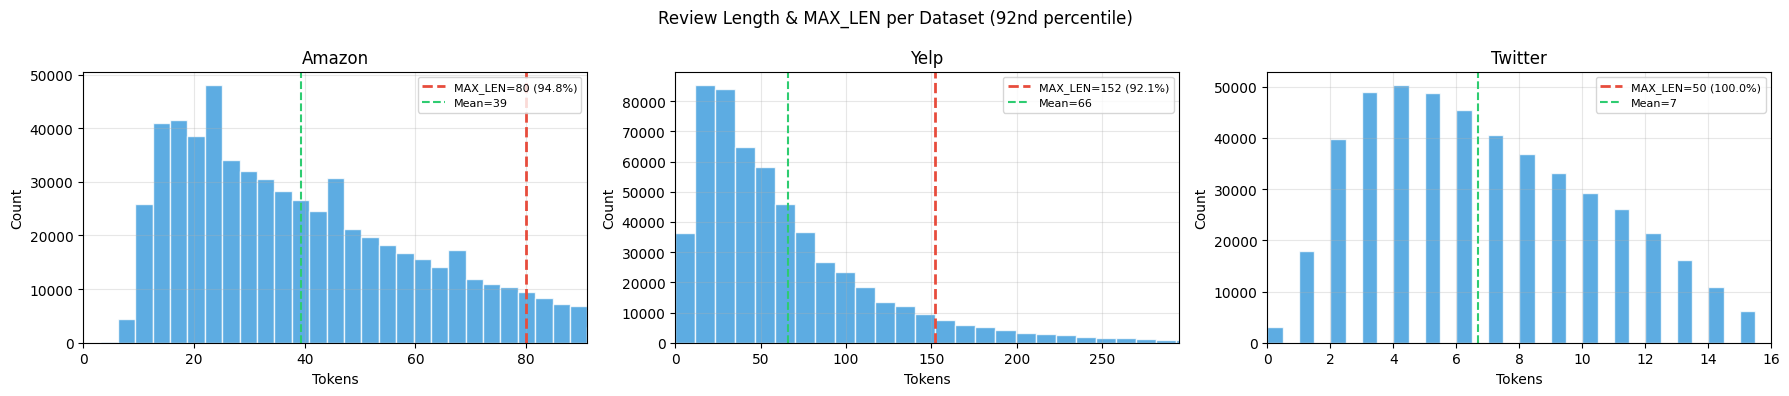


MAX_LEN: {'amazon': 80, 'yelp': 152, 'twitter': 50}


In [4]:
max_len_config = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, ds in zip(axes, DATASETS):
    tr_tok = processed[ds][0]
    lengths = [len(tok) for tok in tr_tok]
    pct92 = int(np.percentile(lengths, 92))
    ml = max(int(np.ceil(pct92/8)*8), 50)   # round to multiple of 8, min 50
    max_len_config[ds] = ml
    cov = sum(1 for l in lengths if l<=ml)/len(lengths)*100

    ax.hist(lengths, bins=50, color="#3498db", alpha=0.8, edgecolor="white")
    ax.axvline(ml, color="#e74c3c", ls="--", lw=2, label=f"MAX_LEN={ml} ({cov:.1f}%)")
    ax.axvline(np.mean(lengths), color="#2ecc71", ls="--", lw=1.5, label=f"Mean={np.mean(lengths):.0f}")
    ax.set_title(f"{ds.capitalize()}"); ax.set_xlabel("Tokens"); ax.set_ylabel("Count")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    ax.set_xlim(0, min(500, int(np.percentile(lengths,99))))

    thresholds = [50, 75, 100, 125, 150, 175, 200, 250, 300]
    print(f"\n{ds.upper()}: MAX_LEN={ml} ({cov:.1f}% coverage)")
    for t in thresholds:
        c_ = sum(1 for l in lengths if l<=t)/len(lengths)*100
        print(f"  <={t:>4}: {c_:.1f}%")

plt.suptitle("Review Length & MAX_LEN per Dataset (92nd percentile)", fontsize=12)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/global/fig_length_coverage.pdf", dpi=300, bbox_inches="tight")
plt.show()
print(f"\nMAX_LEN: {max_len_config}")


## 4. Load FastText

In [5]:
print("Loading fasttext-wiki-news-subwords-300 (~1GB, cached after first run)...")
ft = gensim_api.load("fasttext-wiki-news-subwords-300")
print(f"FastText: dim={ft.vector_size}  vocab={len(ft.key_to_index):,}")

def mean_embed(tokens):
    vecs = [ft[t] for t in tokens if t in ft]
    return (np.mean(vecs, axis=0).astype(np.float32)
            if vecs else np.zeros(EMBED_DIM, dtype=np.float32))

print("mean_embed ready.")


Loading fasttext-wiki-news-subwords-300 (~1GB, cached after first run)...
[==================================================] 100.0% 958.5/958.4MB downloaded
FastText: dim=300  vocab=999,999
mean_embed ready.


## 5. Vocab Coverage

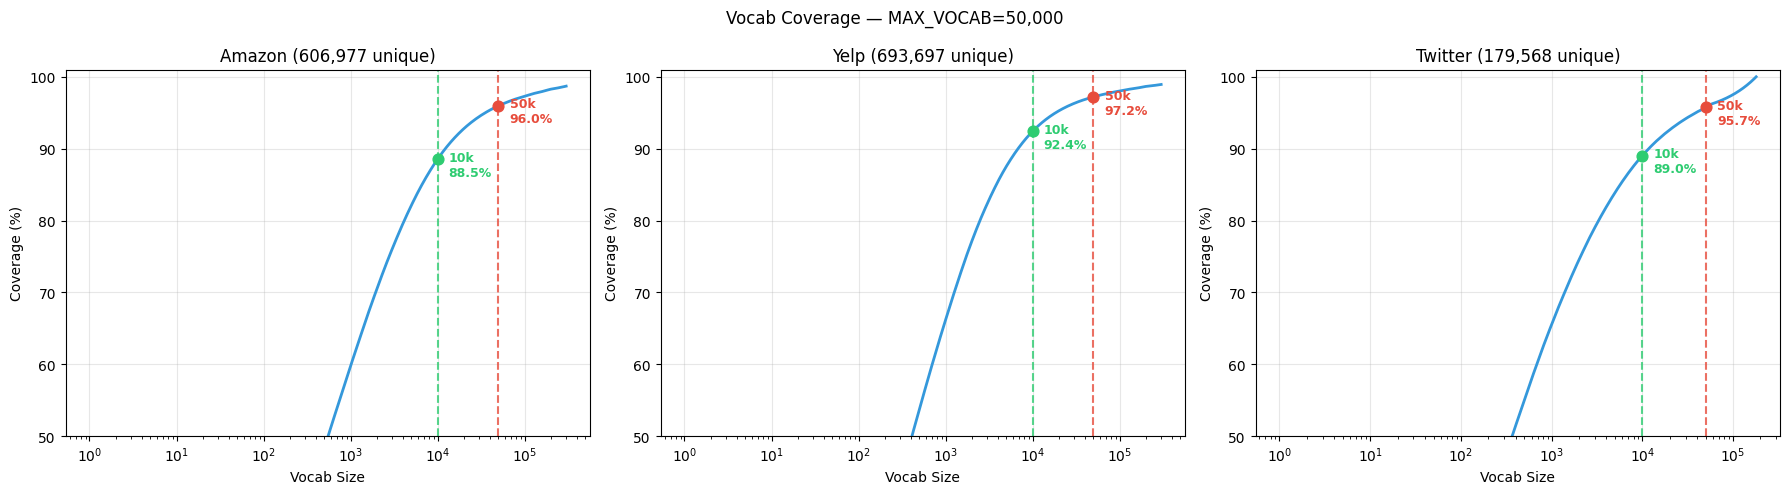

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, ds in zip(axes, DATASETS):
    tr_tok = processed[ds][0]
    all_w  = [w for doc in tr_tok for w in doc]
    wf = Counter(all_w); tu = len(wf)
    cum = np.cumsum(sorted(wf.values(), reverse=True))
    cov = cum/cum[-1]*100
    x_pts = np.arange(1, min(tu+1, 300001))
    ax.plot(x_pts, cov[:len(x_pts)], color="#3498db", lw=2)
    for vsz,col,lbl in [(10000,"#2ecc71","10k"),(MAX_VOCAB,"#e74c3c",f"{MAX_VOCAB//1000}k")]:
        if vsz<=tu:
            c_ = cov[vsz-1]
            ax.axvline(vsz, color=col, ls="--", lw=1.5, alpha=0.8)
            ax.scatter([vsz],[c_], color=col, zorder=5, s=60)
            ax.annotate(f"{lbl}\n{c_:.1f}%",(vsz,c_),
                        textcoords="offset points",xytext=(8,-12),fontsize=9,color=col,fontweight="bold")
    ax.set_xscale("log"); ax.set_xlabel("Vocab Size"); ax.set_ylabel("Coverage (%)")
    ax.set_ylim(50,101); ax.set_title(f"{ds.capitalize()} ({tu:,} unique)"); ax.grid(alpha=0.3)
plt.suptitle(f"Vocab Coverage — MAX_VOCAB={MAX_VOCAB:,}", fontsize=12)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/global/fig_vocab_coverage.pdf", dpi=300, bbox_inches="tight")
plt.show()


## 6. Tokenize, Embed, Split & Save

In [7]:
for ds in DATASETS:
    print(f"\n{'='*55}\n{ds.upper()}\n{'='*55}")
    tr_tok, tr_str, tr_labels, tr_raw,     te_tok, te_str, te_labels, te_raw = processed[ds]
    ml = max_len_config[ds]

    # ── Embeddings (train and test separately) ────────────────────────────────
    print(f"  Train embeddings ({len(tr_tok):,})...")
    X_emb_tr = np.array([mean_embed(tok) for tok in tr_tok], dtype=np.float32)
    print(f"  Test  embeddings ({len(te_tok):,})...")
    X_emb_te = np.array([mean_embed(tok) for tok in te_tok], dtype=np.float32)

    # ── Tokenizer fitted on TRAIN only — no test data leakage ─────────────────
    print(f"  Tokenizing (MAX_LEN={ml}, fit on train only)...")
    tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<OOV>")
    tokenizer.fit_on_texts(tr_str)
    X_seq_tr = pad_sequences(tokenizer.texts_to_sequences(tr_str),
                              maxlen=ml, padding="post", truncating="post").astype(np.int32)
    X_seq_te = pad_sequences(tokenizer.texts_to_sequences(te_str),
                              maxlen=ml, padding="post", truncating="post").astype(np.int32)

    # ── Embedding matrix ──────────────────────────────────────────────────────
    vocab_size = min(MAX_VOCAB, len(tokenizer.word_index)+1)
    emb_mat = np.zeros((vocab_size, EMBED_DIM), dtype=np.float32)
    found = 0
    for word, idx in tokenizer.word_index.items():
        if idx < vocab_size and word in ft:
            emb_mat[idx] = ft[word]; found += 1
    cov_pct = round(100*found/vocab_size, 2)
    print(f"  Emb matrix: {emb_mat.shape} | Coverage: {cov_pct}%")

    # ── Split TRAIN → train/val (75/25) ───────────────────────────────────────
    tr_idx, val_idx = train_test_split(
        np.arange(len(tr_labels)), test_size=0.25,
        stratify=tr_labels, random_state=SEED)

    X_emb_train = X_emb_tr[tr_idx]
    X_emb_val   = X_emb_tr[val_idx]
    X_emb_test  = X_emb_te                    # official test set — untouched
    X_seq_train  = X_seq_tr[tr_idx]
    X_seq_val    = X_seq_tr[val_idx]
    X_seq_test   = X_seq_te                   # official test set — untouched
    y_train = tr_labels[tr_idx]
    y_val   = tr_labels[val_idx]
    y_test  = te_labels                       # official test labels

    X_str_train   = [tr_str[i] for i in tr_idx]
    X_str_val     = [tr_str[i] for i in val_idx]
    X_str_test    = list(te_str)
    test_texts_raw = list(te_raw)

    # Class weights computed on TRAIN split only
    cw = dict(zip(
        [int(k) for k in np.unique(y_train)],
        [float(v) for v in compute_class_weight("balanced",
                            classes=np.unique(y_train), y=y_train)]
    ))
    print(f"  train={len(y_train):,}  val={len(y_val):,}  test={len(y_test):,}")
    print(f"  class_weights: {cw}")

    # ── Save ─────────────────────────────────────────────────────────────────
    d = f"{SHARED_DIR}/{ds}"
    np.save(f"{d}/X_emb_train.npy", X_emb_train)
    np.save(f"{d}/X_emb_val.npy",   X_emb_val)
    np.save(f"{d}/X_emb_test.npy",  X_emb_test)
    np.save(f"{d}/X_seq_train.npy", X_seq_train)
    np.save(f"{d}/X_seq_val.npy",   X_seq_val)
    np.save(f"{d}/X_seq_test.npy",  X_seq_test)
    np.save(f"{d}/y_train.npy",     y_train)
    np.save(f"{d}/y_val.npy",       y_val)
    np.save(f"{d}/y_test.npy",      y_test)
    np.save(f"{d}/train_idx.npy",   tr_idx)
    np.save(f"{d}/val_idx.npy",     val_idx)
    np.save(f"{d}/emb_matrix.npy",  emb_mat)

    for fname, data in [
        ("X_txt_train.txt", X_str_train),
        ("X_txt_val.txt",   X_str_val),
        ("X_txt_test.txt",  X_str_test),
        ("test_texts_raw.txt", test_texts_raw),
    ]:
        with open(f"{d}/{fname}", "w", encoding="utf-8") as f:
            f.write("\n".join(data))

    with open(f"{d}/tokenizer.json", "w") as f:
        f.write(tokenizer.to_json())

    json.dump(cw, open(f"{d}/class_weights.json","w"), indent=2)
    json.dump({
        "dataset": ds, "max_len": ml, "max_vocab": MAX_VOCAB,
        "vocab_size": vocab_size, "embed_dim": EMBED_DIM, "seed": SEED,
        "emb_coverage_pct": cov_pct,
        "n_train": int(len(y_train)), "n_val": int(len(y_val)), "n_test": int(len(y_test)),
        "n_pos_train": int(y_train.sum()), "n_neg_train": int((y_train==0).sum()),
        "imbalance_ratio": round(float(y_train.sum()/max((y_train==0).sum(),1)), 4),
    }, open(f"{d}/config.json","w"), indent=2)

    print(f"  Saved to {d}/")
    del X_emb_tr, X_emb_te, X_seq_tr, X_seq_te, emb_mat
    gc.collect()

del ft; gc.collect()
print("\nFastText freed. All datasets processed and saved.")



AMAZON
  Train embeddings (600,000)...
  Test  embeddings (400,000)...
  Tokenizing (MAX_LEN=80, fit on train only)...
  Emb matrix: (50000, 300) | Coverage: 82.01%
  train=450,000  val=150,000  test=400,000
  class_weights: {0: 1.0, 1: 1.0}
  Saved to /kaggle/working/shared_data/amazon/

YELP
  Train embeddings (560,000)...
  Test  embeddings (38,000)...
  Tokenizing (MAX_LEN=152, fit on train only)...
  Emb matrix: (50000, 300) | Coverage: 71.38%
  train=420,000  val=140,000  test=38,000
  class_weights: {0: 1.0, 1: 1.0}
  Saved to /kaggle/working/shared_data/yelp/

TWITTER
  Train embeddings (480,000)...
  Test  embeddings (120,000)...
  Tokenizing (MAX_LEN=50, fit on train only)...
  Emb matrix: (50000, 300) | Coverage: 68.33%
  train=360,000  val=120,000  test=120,000
  class_weights: {0: 1.0000555586421467, 1: 0.9999444475306928}
  Saved to /kaggle/working/shared_data/twitter/

FastText freed. All datasets processed and saved.


## 7. Baselines (GPU — all 3 datasets)

In [8]:
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
tf.keras.mixed_precision.set_global_policy("mixed_float16")
strategy = tf.distribute.MirroredStrategy()
N_GPUS    = strategy.num_replicas_in_sync
ANN_BATCH = 1024 * N_GPUS
CNN_BATCH = 128  * N_GPUS

def set_seeds_tf(seed=SEED):
    set_seeds(seed); tf.random.set_seed(seed)

def evaluate(name, y_true, y_pred, y_prob=None):
    auc = round(roc_auc_score(y_true, y_prob), 4) if y_prob is not None else float("nan")
    ap  = round(average_precision_score(y_true, y_prob), 4) if y_prob is not None else float("nan")
    rep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    return {
        "Model"       : name,
        "Accuracy"    : round(accuracy_score(y_true, y_pred), 4),
        "Precision"   : round(precision_score(y_true, y_pred, zero_division=0), 4),
        "Recall"      : round(recall_score(y_true, y_pred, zero_division=0), 4),
        "F1-score"    : round(f1_score(y_true, y_pred, zero_division=0), 4),
        "Macro-F1"    : round(rep["macro avg"]["f1-score"], 4),
        "Weighted-F1" : round(rep["weighted avg"]["f1-score"], 4),
        "MCC"         : round(matthews_corrcoef(y_true, y_pred), 4),
        "AUC-ROC"     : auc, "Avg-Precision": ap,
    }

def make_es(p=5):
    return EarlyStopping(monitor="val_loss", patience=p,
                         restore_best_weights=True, verbose=1)

def make_tf_ds(X, y, batch, shuffle=True, seed=SEED):
    ds = tf.data.Dataset.from_tensor_slices(
        (X.astype(np.float32), y.astype(np.float32)))
    if shuffle: ds = ds.shuffle(min(len(y),50000), seed=seed)
    return ds.batch(batch).cache().prefetch(tf.data.AUTOTUNE)

def make_seq_ds(X, y, batch, shuffle=True, seed=SEED):
    ds = tf.data.Dataset.from_tensor_slices(
        (X.astype(np.int32), y.astype(np.float32)))
    if shuffle: ds = ds.shuffle(min(len(y),50000), seed=seed)
    return ds.batch(batch).cache().prefetch(tf.data.AUTOTUNE)

print(f"GPUs={N_GPUS}  ANN_BATCH={ANN_BATCH}  CNN_BATCH={CNN_BATCH}")
set_seeds_tf()


GPUs=2  ANN_BATCH=2048  CNN_BATCH=256


I0000 00:00:1780265755.585076      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1780265755.591345      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [9]:
for ds in DATASETS:
    print(f"\n{'='*55}\nBASELINES | {ds.upper()}\n{'='*55}")

    d      = f"{SHARED_DIR}/{ds}"
    cfg    = json.load(open(f"{d}/config.json"))
    ml     = cfg["max_len"]; vs = cfg["vocab_size"]

    X_emb_tr  = np.load(f"{d}/X_emb_train.npy")
    X_emb_vl  = np.load(f"{d}/X_emb_val.npy")
    X_emb_te  = np.load(f"{d}/X_emb_test.npy")
    X_seq_tr  = np.load(f"{d}/X_seq_train.npy")
    X_seq_vl  = np.load(f"{d}/X_seq_val.npy")
    X_seq_te  = np.load(f"{d}/X_seq_test.npy")
    y_tr = np.load(f"{d}/y_train.npy")
    y_vl = np.load(f"{d}/y_val.npy")
    y_te = np.load(f"{d}/y_test.npy")
    emb_mat = np.load(f"{d}/emb_matrix.npy")
    cw = {int(k):float(v) for k,v in
          json.load(open(f"{d}/class_weights.json")).items()}

    with open(f"{d}/X_txt_train.txt",encoding="utf-8") as f: X_txt_tr=f.read().splitlines()
    with open(f"{d}/X_txt_val.txt",  encoding="utf-8") as f: X_txt_vl=f.read().splitlines()
    with open(f"{d}/X_txt_test.txt", encoding="utf-8") as f: X_txt_te=f.read().splitlines()

    # Train+Val combined for baselines + recomputed class weights
    X_emb_tv = np.vstack([X_emb_tr, X_emb_vl])
    X_seq_tv  = np.vstack([X_seq_tr, X_seq_vl])
    y_tv      = np.concatenate([y_tr, y_vl])
    X_txt_tv  = X_txt_tr + X_txt_vl
    cw_tv = dict(zip(
        [int(k) for k in np.unique(y_tv)],
        [float(v) for v in compute_class_weight("balanced",
                            classes=np.unique(y_tv), y=y_tv)]
    ))
    n_es = int(len(y_tv)*0.1)   # last 10% of tv for early stopping
    results = []

    # TF-IDF + LR
    print("  TF-IDF + LR...")
    lr_pipe = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=50000, ngram_range=(1,2), sublinear_tf=True)),
        ("clf",   LogisticRegression(max_iter=1000, solver="lbfgs", random_state=SEED)),
    ])
    lr_pipe.fit(X_txt_tv, y_tv)
    lr_pred = lr_pipe.predict(X_txt_te)
    lr_prob = lr_pipe.predict_proba(X_txt_te)[:,1]
    r = evaluate("TF-IDF + LR", y_te, lr_pred, lr_prob)
    results.append(r); print(f"    F1={r['F1-score']}  MCC={r['MCC']}")

    # TF-IDF + SVM
    print("  TF-IDF + SVM...")
    svm_pipe = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=50000, ngram_range=(1,2), sublinear_tf=True)),
        ("clf",   LinearSVC(max_iter=3000, random_state=SEED, dual=False)),
    ])
    svm_pipe.fit(X_txt_tv, y_tv)
    svm_pred   = svm_pipe.predict(X_txt_te)
    svm_scores = svm_pipe.decision_function(X_txt_te)
    r = evaluate("TF-IDF + SVM", y_te, svm_pred, svm_scores)
    results.append(r); print(f"    F1={r['F1-score']}  MCC={r['MCC']}")

    # Default ANN
    print(f"  Default ANN (batch={ANN_BATCH})...")
    set_seeds_tf()
    with strategy.scope():
        ann_def = tf.keras.Sequential([
            tf.keras.layers.Dense(128, activation="relu", input_shape=(EMBED_DIM,)),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(64,  activation="relu"),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(1,   activation="sigmoid", dtype="float32"),
        ])
        ann_def.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                        loss="binary_crossentropy", metrics=["accuracy"])
    ann_def.fit(
        make_tf_ds(X_emb_tv[:-n_es], y_tv[:-n_es], ANN_BATCH),
        validation_data=make_tf_ds(X_emb_tv[-n_es:], y_tv[-n_es:], ANN_BATCH, shuffle=False),
        epochs=50, callbacks=[make_es(5)], class_weight=cw_tv, verbose=1)
    ann_def_prob = ann_def.predict(
        make_tf_ds(X_emb_te, np.zeros(len(y_te)), ANN_BATCH, shuffle=False),
        verbose=1).flatten()
    ann_def_pred = (ann_def_prob>0.5).astype(int)
    r = evaluate("Default ANN", y_te, ann_def_pred, ann_def_prob)
    results.append(r); print(f"    F1={r['F1-score']}  MCC={r['MCC']}")

    # Default CNN+BiLSTM
    print(f"  Default CNN+BiLSTM (batch={CNN_BATCH})...")
    set_seeds_tf()
    with strategy.scope():
        cnn_def = tf.keras.Sequential([
            tf.keras.layers.Embedding(vs, EMBED_DIM, weights=[emb_mat], trainable=False),
            tf.keras.layers.Conv1D(128, 3, activation="relu"),
            tf.keras.layers.MaxPooling1D(2),
            tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64)),
            tf.keras.layers.Dense(64, activation="relu"),
            tf.keras.layers.Dropout(0.5),
            tf.keras.layers.Dense(1,  activation="sigmoid", dtype="float32"),
        ])
        cnn_def.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                        loss="binary_crossentropy", metrics=["accuracy"])
    cnn_def.fit(
        make_seq_ds(X_seq_tv[:-n_es], y_tv[:-n_es], CNN_BATCH),
        validation_data=make_seq_ds(X_seq_tv[-n_es:], y_tv[-n_es:], CNN_BATCH, shuffle=False),
        epochs=20, callbacks=[make_es(3)], class_weight=cw_tv, verbose=1)
    cnn_def_prob = cnn_def.predict(
        make_seq_ds(X_seq_te, np.zeros(len(y_te)), CNN_BATCH, shuffle=False),
        verbose=1).flatten()
    cnn_def_pred = (cnn_def_prob>0.5).astype(int)
    r = evaluate("Default CNN+BiLSTM", y_te, cnn_def_pred, cnn_def_prob)
    results.append(r); print(f"    F1={r['F1-score']}  MCC={r['MCC']}")

    # Save
    np.save(f"{d}/lr_prob.npy",      lr_prob)
    np.save(f"{d}/svm_scores.npy",   svm_scores)
    np.save(f"{d}/ann_def_prob.npy", ann_def_prob)
    np.save(f"{d}/cnn_def_prob.npy", cnn_def_prob)

    m_dir = f"{MODELS_DIR}/{ds}"
    with open(f"{m_dir}/tfidf_lr.pkl","wb")  as f: pickle.dump(lr_pipe,  f)
    with open(f"{m_dir}/tfidf_svm.pkl","wb") as f: pickle.dump(svm_pipe, f)
    ann_def.save(f"{m_dir}/default_ann.keras")
    cnn_def.save(f"{m_dir}/default_cnn.keras")

    r_dir = f"{RESULTS_DIR}/{ds}"
    pd.DataFrame(results).to_csv(f"{r_dir}/baseline_metrics.csv", index=False)
    json.dump(
        {r_["Model"]:{k:v for k,v in r_.items() if k!="Model"} for r_ in results},
        open(f"{r_dir}/baseline_metrics.json","w"), indent=2)

    print(f"\n  {ds} baselines saved.")
    for res in results:
        print(f"    {res['Model']:25s}: F1={res['F1-score']}  MCC={res['MCC']}")

    del ann_def, cnn_def, X_emb_tv, X_seq_tv, emb_mat
    gc.collect()

print("\nAll baselines complete.")



BASELINES | AMAZON
  TF-IDF + LR...
    F1=0.9097  MCC=0.8187
  TF-IDF + SVM...
    F1=0.9099  MCC=0.8194
  Default ANN (batch=2048)...
Epoch 1/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.7953 - loss: 0.4471 - val_accuracy: 0.8374 - val_loss: 0.3701
Epoch 2/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8404 - loss: 0.3655 - val_accuracy: 0.8445 - val_loss: 0.3556
Epoch 3/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8464 - loss: 0.3549 - val_accuracy: 0.8487 - val_loss: 0.3483
Epoch 4/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8501 - loss: 0.3483 - val_accuracy: 0.8515 - val_loss: 0.3427
Epoch 5/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8528 - loss: 0.3434 - val_accuracy: 0.8528 - val_loss: 0.3392
Epoch 6/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8545 - loss: 0.3402 - val_accuracy: 0.8543 - val_loss: 0.3360
Epoch 7/50
264/264 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8561 - loss: 0.3367 -

I0000 00:00:1780266247.800339      72 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1780266247.800356      71 cuda_dnn.cc:529] Loaded cuDNN version 91002


2110/2110 ━━━━━━━━━━━━━━━━━━━━ 40s 17ms/step - accuracy: 0.8612 - loss: 0.3214 - val_accuracy: 0.8874 - val_loss: 0.2665
Epoch 2/20
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 33s 15ms/step - accuracy: 0.8641 - loss: nan - val_accuracy: 0.4997 - val_loss: nan
Epoch 3/20
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 27s 13ms/step - accuracy: 0.5000 - loss: nan - val_accuracy: 0.4997 - val_loss: nan
Epoch 4/20
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 28s 13ms/step - accuracy: 0.5000 - loss: nan - val_accuracy: 0.4997 - val_loss: nan
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step
    F1=0.8875  MCC=0.7769

  amazon baselines saved.
    TF-IDF + LR              : F1=0.9097  MCC=0.8187
    TF-IDF + SVM             : F1=0.9099  MCC=0.8194
    Default ANN              : F1=0.868  MCC=0.7371
    Default CNN+BiLSTM       : F1=0.8875  MCC=0.7769

BASELINES | YELP
  TF-IDF + LR...
    F1=0.9409  MCC=0.8815
  TF-IDF + SVM...
    F1=0.9421  MCC=0.8841
  De

## 8. Summary

In [10]:
print("=== NB01 Complete ===\n")
for ds in DATASETS:
    cfg = json.load(open(f"{SHARED_DIR}/{ds}/config.json"))
    print(f"{ds.upper()}:")
    print(f"  MAX_LEN={cfg['max_len']}  vocab={cfg['vocab_size']:,}  emb_cov={cfg['emb_coverage_pct']}%")
    print(f"  train={cfg['n_train']:,}  val={cfg['n_val']:,}  test={cfg['n_test']:,}  ratio={cfg['imbalance_ratio']}:1")
    r = json.load(open(f"{RESULTS_DIR}/{ds}/baseline_metrics.json"))
    for name,m in r.items():
        print(f"  {name:25s}: F1={m['F1-score']}  MCC={m['MCC']}")
    print()
print("Files saved per dataset:")
for ds in DATASETS:
    files = sorted(os.listdir(f"{SHARED_DIR}/{ds}"))
    print(f"  {ds}: {len(files)} files in shared_data/{ds}/")
print("\nNext: run NB02 + NB03 (can run in parallel — both only need NB01)")


=== NB01 Complete ===

AMAZON:
  MAX_LEN=80  vocab=50,000  emb_cov=82.01%
  train=450,000  val=150,000  test=400,000  ratio=1.0:1
  TF-IDF + LR              : F1=0.9097  MCC=0.8187
  TF-IDF + SVM             : F1=0.9099  MCC=0.8194
  Default ANN              : F1=0.868  MCC=0.7371
  Default CNN+BiLSTM       : F1=0.8875  MCC=0.7769

YELP:
  MAX_LEN=152  vocab=50,000  emb_cov=71.38%
  train=420,000  val=140,000  test=38,000  ratio=1.0:1
  TF-IDF + LR              : F1=0.9409  MCC=0.8815
  TF-IDF + SVM             : F1=0.9421  MCC=0.8841
  Default ANN              : F1=0.8981  MCC=0.7944
  Default CNN+BiLSTM       : F1=0.9217  MCC=0.8433

TWITTER:
  MAX_LEN=50  vocab=50,000  emb_cov=68.33%
  train=360,000  val=120,000  test=120,000  ratio=1.0001:1
  TF-IDF + LR              : F1=0.7889  MCC=0.5701
  TF-IDF + SVM             : F1=0.7807  MCC=0.5531
  Default ANN              : F1=0.7701  MCC=0.5381
  Default CNN+BiLSTM       : F1=0.7666  MCC=0.5329

Files saved per dataset:
  amazon: 23 fi